<h1> Frozen Lake MDP

Steps:

- Gymnasium installation and testing
- Creating the FrozenLake environment
- Displaying the grid
- Extraction:
    - States
    - Actions
    - Transition probability
    - Reward

FrozenLake is one of the classic Gymnasium environments.

Environment:

SFFF</br>
FHFH</br>
FFFH</br>
HFFG

Cells Meaning:

| Symbol | Meaning |
|-|-|
| S | Starting point |
| F | Frozen surface |
| H | Hole (failure) |
| G | Goal |

In [175]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

<h3> Step 1: Build The Environment 

Why `is_slippery=False`?

The original FrozenLake is stochastic.

This means that if you specify:
`action = RIGHT`

You might:
- move right
- slip
- end up somewhere else

This implies the existence of transition probabilities.
However, for the initial setup, it is better to use a deterministic approach.

Later, for a true MDP, we can explore:
`is_slippery=True`

In [176]:
env = gym.make(
    "FrozenLake-v1",
    is_slippery=False,
    render_mode="rgb_array"
)

Observing The State and Action Space

In [177]:
print(env.observation_space)

print(env.action_space)

Discrete(16)
Discrete(4)


States = 16 states:

$S=\{0,1,...,15\}$

Since the grid is 4x4.

Actions = 4 moves:</br>
- 0 → Left
- 1 → Down
- 2 → Right
- 3 → Up

Reset Environment

In [178]:
state, info = env.reset()

print(state)

0


One Simple Step

In [179]:
next_state, reward, terminated, truncated, info = env.step(2)

print(
    next_state,
    reward,
    terminated,
    truncated,
    info
)

1 0 False False {'prob': 1.0}


#### This is the result of executing:

1. env.step(2) means: Action = Right
2. Agent moved from State=0 to State=1, and the move to the right was successful.
3. Reward=0 because it hasn't reached the goal yet.
4. terminated = False, This means the episode has not ended yet; it has:
    - not reached the goal
    - not fallen into a hole
5. truncated = False, This means it did not stop due to time limits or the number of steps.
6. is_slippery=False, So the transition is completely deterministic.

Environment Display

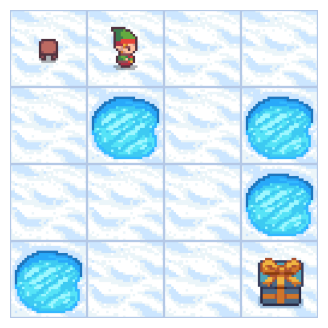

In [180]:
img = env.render()

plt.figure(figsize=(4,4))
plt.imshow(img)
plt.axis("off")
plt.show()

Review of the Transition Model

env.P is the MDP model.

This is the most important output of the MDP.</br>
This output is exactly the definition of the transition function::

$P(s'|s,a)$

In [181]:
env.unwrapped.P[0]

{0: [(1.0, 0, 0, False)],
 1: [(1.0, 4, 0, False)],
 2: [(1.0, 1, 0, False)],
 3: [(1.0, 0, 0, False)]}

Example:

0: [(1.0, 0, 0, False)]

- Action 0 → Left
- Probability = 1.0
- Next state = 0
- Reward = 0
- Done = False

Since we are at the edge of the grid, moving left causes us to stay in the same spot.

In [182]:
for action in env.unwrapped.P[0]:
    print(action)

0
1
2
3


<h3> Step 2: Random Policy

Before optimization, create a random policy:

In [183]:
policy = np.ones(
    (
        env.observation_space.n,
        env.action_space.n
    )
) / env.action_space.n

This is our initial policy.

Dimensions:
16 × 4

This means that for each state, we have four actions.

This policy possesses no knowledge. That is why it is called a Random Policy.

In Policy Iteration, this same matrix subsequently changes:
From:</br>
0.25 0.25 0.25 0.25

To something like:</br>
0    0    1    0

Meaning:</br>
Always choose "Right" in this state.

In [184]:
policy

array([[0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25]])

### FrozenLake MDP Setup

The FrozenLake environment was modeled as a Markov Decision Process.

The environment contains:

- 16 discrete states representing grid positions.
- 4 possible actions: Left, Down, Right, and Up.
- A deterministic transition model because `is_slippery=False`.
- Rewards are received only when reaching the goal state.

The transition function `P(s'|s,a)` was extracted from the environment and will be used later for Dynamic Programming algorithms.

A random policy was initialized where every action has equal probability (0.25) in every state. This policy will be improved using Policy Iteration and Value Iteration.

<h3> Step 3: Random Agent 

The goal is to see how well an agent can solve FrozenLake using only random choices, without any learning.
This step is important because later, when we implement Policy Iteration and Value Iteration, we will be able to ask:
Did our algorithm actually perform better than a random policy?

The idea is simple:
In each state:
We have no knowledge.
So:
Choose a random action.

Executing an episode

In [185]:
def run_random_episode(env):

    state, info = env.reset()

    total_reward = 0
    steps = 0

    while True:

        action = env.action_space.sample()

        state, reward, terminated, truncated, info = env.step(action)

        total_reward += reward
        steps += 1

        if terminated or truncated:
            break

    return total_reward, steps

In [186]:
reward, steps = run_random_episode(
    env
)

print(
    "Reward:",
    reward
)

print(
    "Steps:",
    steps
)

Reward: 0
Steps: 9


In [187]:
def run_random_episode_debug(env):

    state, info = env.reset()

    path = [state]

    total_reward = 0
    steps = 0

    while True:

        action = env.action_space.sample()

        state, reward, terminated, truncated, info = env.step(action)

        path.append(state)

        total_reward += reward
        steps += 1

        if terminated or truncated:
            break

    return total_reward, steps, path, terminated

In [188]:
reward, steps, path, terminated = run_random_episode_debug(env)

print("Reward:", reward)
print("Steps:", steps)
print("Path:", path)

Reward: 1
Steps: 10
Path: [0, 4, 4, 4, 4, 4, 8, 9, 13, 14, 15]


#### Running several episodes

In [189]:
episodes = 1000

success = 0
steps_list = []

for _ in range(episodes):

    reward, steps = run_random_episode(env)

    if reward == 1:
        success += 1

    steps_list.append(
        steps
    )


print(
    "Success rate:",
    success / episodes
)

Success rate: 0.015


In other words, the agent reached the goal approximately once or twice every 100 episodes.

This result is entirely logical.
Because the agent:
- Does not recognize states
- Does not consider rewards
- Does not learn from previous paths
- Does not develop a better policy

#### Visualization Success Rate

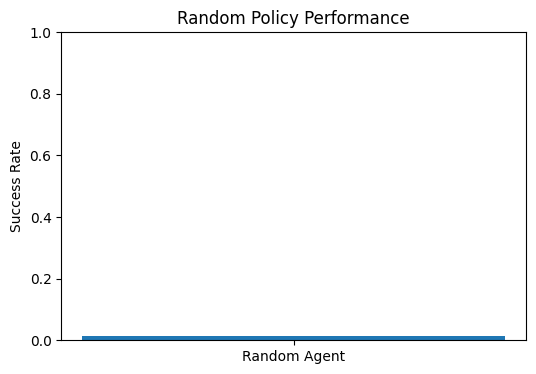

In [190]:
plt.figure(figsize=(6,4))

plt.bar(
    ["Random Agent"],
    [success / episodes]
)

plt.ylabel(
    "Success Rate"
)

plt.title(
    "Random Policy Performance"
)

plt.ylim(
    0,
    1
)

plt.show()

It shows a line hovering near zero.
This means:
Random Agent ≈ No Learning

There is no upward trend.
If we run 1,000 episodes:
- Episode 1
- Episode 500
- Episode 1,000
There is no difference.
Because the agent learns nothing.

### Random Policy Baseline

A random agent was evaluated before applying Dynamic Programming methods.

The agent selects actions uniformly without considering states, rewards, or transition probabilities.

The experiment achieved a low success rate (~1.5%), demonstrating that random exploration is inefficient in environments with sparse rewards.

This baseline provides a reference point for evaluating the improvement achieved by Policy Iteration and Value Iteration.